# Comparación de detectores — sin aumentos contra con aumentos

Proyecto final de Machine Learning y de Redes Neuronales y Deep Learning (EAFIT 2026-2).

**Pregunta.** Los dos detectores YOLO11n de una sola clase (`item` = huevo) rinden igual en `valid` de Chula
(mAP50-95 0,927 sin aumentos y 0,924 con aumentos). ¿Los aumentos de color y calidad le sirven con fotos de
celular tomadas por el ocular? ¿Con qué seguridad (puntaje) marca cada modelo los huevos y las falsas alarmas?

**Lo que se compara.** Los dos se entrenaron en la misma CPU (`bigmem`), con la misma semilla y el mismo split;
solo cambian los aumentos (`hsv_*` y los de `data/aug`: desenfoque, ruido, JPEG, viñeta, puntero).

**Datos.** (a) Fotos externas de celular en `data/external/` con su conteo de huevos en `external.csv`;
(b) las 410 fotos de `valid` de Chula, con sus cajas reales. `test` no se usa.

**Cómo correrlo.** Desde la raíz del repo, con el kernel `Python (geohelmintos)`. Corre en CPU, sin GPU.

## Reglas de la comparación

| Tema | Regla |
|---|---|
| Modelos | Sin aumentos y con aumentos (los dos en CPU). Si se corre el diseño 2 × 2 en GPU, se agregan como filas en `MODELS`. |
| Fotos de prueba | Las de `uso = prueba` en `external.csv`. Las de `uso = desarrollo` se muestran en las imágenes, pero **no cuentan** en ninguna tabla ni métrica. |
| Fotos no independientes | `a-image2.png` se miró al diseñar los aumentos (puntero, viñeta). Debe figurar como `desarrollo`, y el notebook avisa si no es así. |
| Umbral | Uno solo: `CONF_THRESHOLD = 0,25` (ver la decisión abajo). La sección 6 muestra qué pasaría con otros. |
| Resultado principal | Cuatro casillas: huevos **encontrados**, **perdidos** (falsos negativos) y **falsas alarmas** (falsos positivos). |
| Alcance | Son pocas fotos: se reporta como indicio, no como estadística. |

**Limitación del conteo.** Las fotos externas no tienen cajas dibujadas, solo el número de huevos. No se puede
emparejar cada caja con un huevo real (IoU), así que "encontrado", "perdido" y "falsa alarma" se calculan por
conteo y se confirman **mirando las cajas** (sección 3). Si se dibujan las cajas más adelante (PLAN §5.7), esta
parte se vuelve exacta. En `valid` de Chula sí hay cajas reales, y ahí el emparejamiento es exacto (sección 8).

## Decisión: un solo umbral de 0,25

Una caja cuenta como detección si su puntaje es de al menos **0,25**.

- **De dónde sale:** es el valor por defecto de Ultralytics y un punto intermedio. No se optimizó con estos datos:
  era el umbral principal desde el diseño del notebook. El notebook se corrió una vez también con 0,10 y se
  decidió dejar solo 0,25.
- **Los dos errores no cuestan igual.** En un uso médico, un huevo perdido pesa más que una falsa alarma: la
  falsa alarma la descarta quien revisa la caja, y el conteo del HPG se multiplica por 24, así que perder un huevo
  en una infección leve cambia mucho el resultado. Por eso, en el sistema final podría convenir un umbral más
  bajo, y un umbral alto (por ejemplo 0,7) pierde huevos reales con puntaje bajo. La curva de la sección 6
  muestra ese compromiso.
- **Los puntajes no son probabilidades.** 0,25 no significa 25 % de probabilidad, ni 0,93 un 93 % de aciertos.
- **Es provisional.** El umbral definitivo se calibra con más fotos externas con cajas dibujadas y con el
  clasificador, que filtra lo que el detector deja pasar.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch, Rectangle
from PIL import Image
from ultralytics import YOLO

In [2]:
ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
EXTERNAL_DIR = ROOT / "data" / "external"
EXTERNAL_CSV = EXTERNAL_DIR / "external.csv"
VALID_IMAGES_DIR = ROOT / "data" / "raw" / "valid" / "images"
VALID_LABELS_DIR = ROOT / "data" / "raw" / "valid" / "labels"
IMAGE_SUFFIXES = (".jpg", ".jpeg", ".png", ".bmp")

MODELS = {
    "No augmentation": ROOT / "artifacts/yolo/g_single_plain/weights/best.pt",
    "Augmentation": ROOT / "artifacts/yolo/h_single_aug/weights/best.pt",
}

# One color per model, used in every plot of this notebook
MODEL_COLORS = dict(zip(MODELS, ["#eb6834", "#2a78d6", "#1baf7a", "#8a8984"]))
INK, NOT_COUNTED = "#0b0b0b", "#e6e5e1"

# Photos that were looked at while designing the augmentations: not an independent test
PHOTOS_USED_TO_DESIGN_AUGMENTATIONS = {"a-image2.png"}

CONF_THRESHOLD = 0.25   # a box is a detection from this score up (see the decision above)
CONF_CURVE = [round(conf, 2) for conf in np.arange(0.05, 0.96, 0.05)]
CONF_LOWEST = 0.001     # inference keeps every box above this; the threshold is applied afterwards
MAX_BOXES_PER_PHOTO = 50
IMAGE_SIZE = 640        # same size the detectors were trained with
DEVICE = "cpu"
MATCH_IOU = 0.5         # valid only: a box is the egg if it overlaps the real box at least this much

assert all(path.is_file() for path in MODELS.values()), "missing weights"

## 1. Fotos externas y conteo de referencia

Se lee `external.csv` (`image`, `n_items`, `species`, `uso`, `notes`) y se comprueba que cada foto de la carpeta
tenga su fila y que `n_items` esté lleno. Las fotos de `prueba` son las que cuentan; las de `desarrollo` solo
se muestran en las imágenes.

La celda avisa si un campo con `n_items = 0` tiene especie (no debería) o si una foto que inspiró los aumentos
figura como `prueba`.

In [3]:
external_photos = pd.read_csv(EXTERNAL_CSV)

photos_on_disk = {p.name for p in EXTERNAL_DIR.iterdir() if p.suffix.lower() in IMAGE_SUFFIXES}
photos_in_csv = set(external_photos.image)
print("Photos without a row in external.csv:", sorted(photos_on_disk - photos_in_csv) or "none")
print("Rows without a photo on disk:", sorted(photos_in_csv - photos_on_disk) or "none")
print("Rows with an empty n_items:", external_photos[external_photos.n_items.isna()].image.tolist() or "none")
assert photos_on_disk == photos_in_csv and external_photos.n_items.notna().all(), "fix external.csv first"

external_photos["n_items"] = external_photos.n_items.astype(int)
external_photos["has_eggs"] = external_photos.n_items > 0

# An empty field should not carry a species: ask whoever filled the CSV
contradictions = external_photos[(external_photos.n_items == 0) & external_photos.species.notna()]
print("Empty fields that have a species:", contradictions.image.tolist() or "none")

test_photos = external_photos[external_photos.uso == "prueba"]
development_photos = external_photos[external_photos.uso == "desarrollo"]
not_independent = PHOTOS_USED_TO_DESIGN_AUGMENTATIONS & set(test_photos.image)
if not_independent:
    print("Warning: these test photos inspired the augmentations, so they favour the augmented model:",
          sorted(not_independent))

print(f"\n{len(test_photos)} test photos with {test_photos.n_items.sum()} eggs "
      f"({(~test_photos.has_eggs).sum()} without eggs); "
      f"{len(development_photos)} development photo(s), shown but not counted")

Photos without a row in external.csv: none
Rows without a photo on disk: none
Rows with an empty n_items: none
Empty fields that have a species: none

6 test photos with 8 eggs (1 without eggs); 1 development photo(s), shown but not counted


## 2. Inferencia

Cada modelo se corre **una sola vez** sobre cada foto con un umbral casi nulo (`CONF_LOWEST`) y se guardan todas
las cajas con su puntaje. El umbral de las secciones siguientes se aplica después sobre esa tabla, sin volver a
correr el modelo. Resultado: `external_boxes`, con una fila por caja (`model`, `image`, `score`, `x1`, `y1`,
`x2`, `y2`, en píxeles de la foto original).

In [4]:
def detect_all(weights_path, image_paths):
    """Every box the model finds in each image (down to CONF_LOWEST), one row per box."""
    model = YOLO(str(weights_path))
    results = model.predict(
        source=[str(path) for path in image_paths], imgsz=IMAGE_SIZE, conf=CONF_LOWEST,
        max_det=MAX_BOXES_PER_PHOTO, device=DEVICE, stream=True, verbose=False,
    )
    rows = []
    for result in results:
        for (x1, y1, x2, y2), score in zip(result.boxes.xyxy.tolist(), result.boxes.conf.tolist()):
            rows.append({"image": Path(result.path).name, "score": score,
                         "x1": x1, "y1": y1, "x2": x2, "y2": y2})
    return pd.DataFrame(rows, columns=["image", "score", "x1", "y1", "x2", "y2"])


external_paths = [EXTERNAL_DIR / name for name in external_photos.image]
external_boxes = pd.concat(
    [detect_all(weights, external_paths).assign(model=model_name)
     for model_name, weights in MODELS.items()],
    ignore_index=True,
)
display(external_boxes.groupby("model").size().rename("boxes found (any score)"))

model
Augmentation       12
No augmentation    10
Name: boxes found (any score), dtype: int64

## 3. Las cajas sobre cada foto

Una fila por modelo y una columna por foto, con las cajas que llegan a `CONF_THRESHOLD` y su puntaje encima.
Es la forma de confirmar a ojo que una caja está sobre un huevo y no sobre un grumo. En el título de cada foto
aparece cuántos huevos hay de verdad; la de desarrollo se marca como tal.

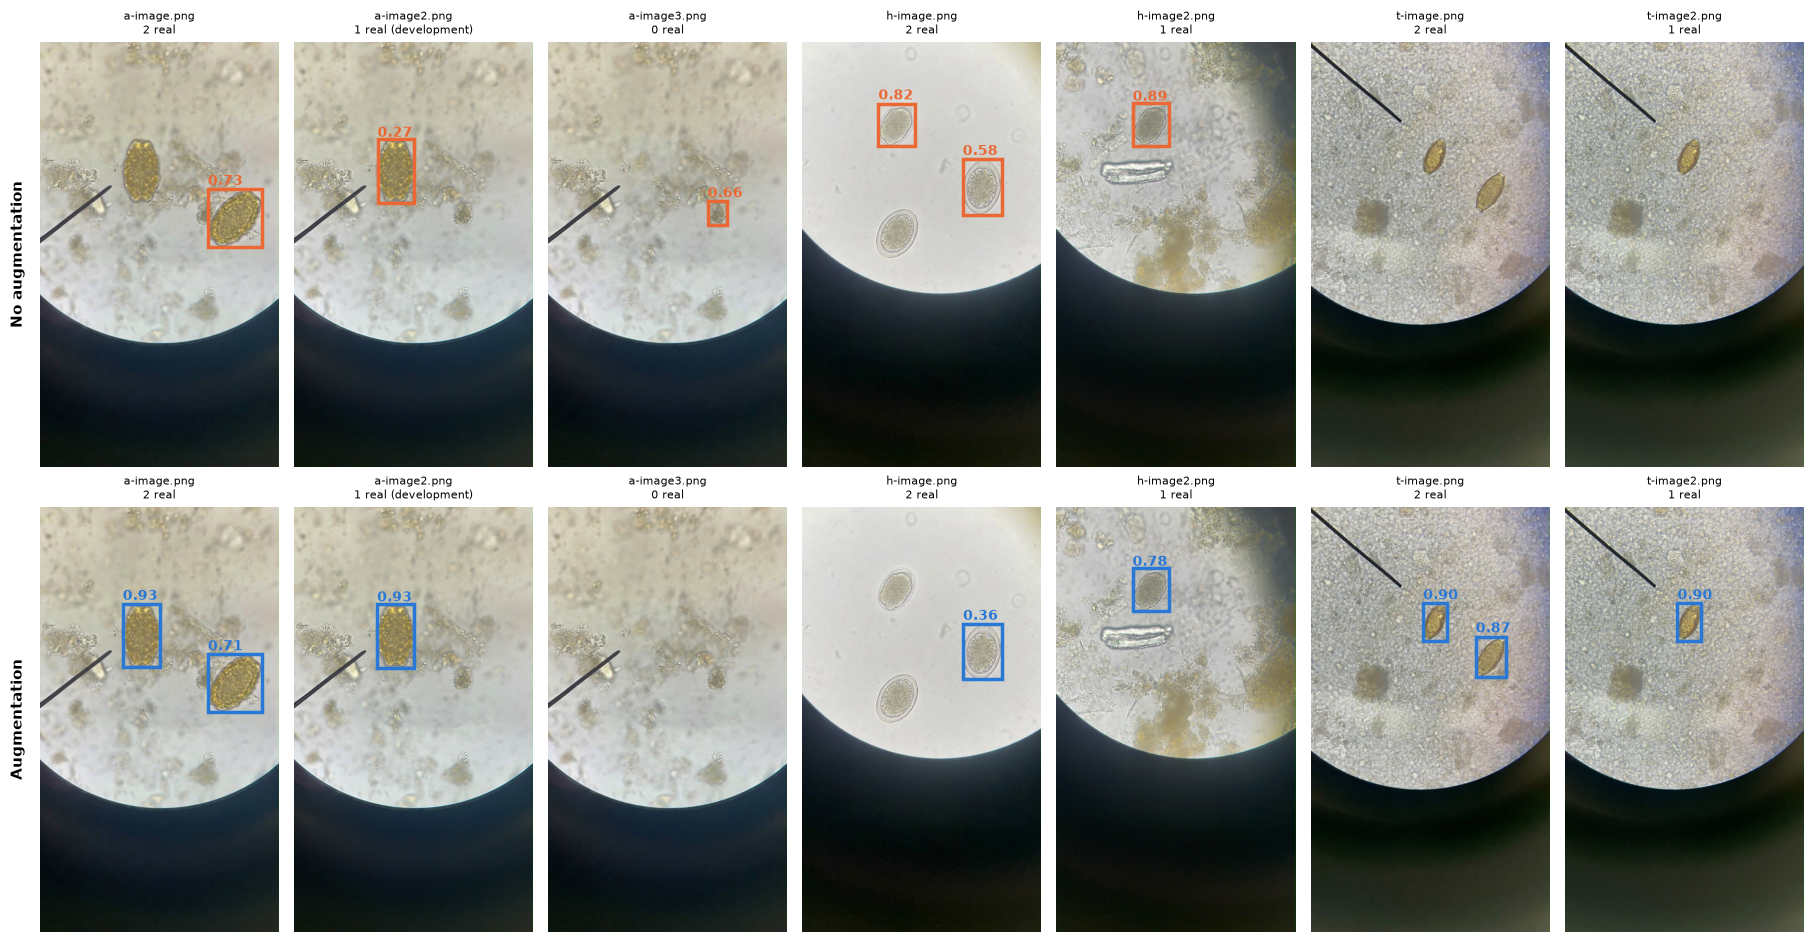

In [5]:
def draw_detections(ax, image_name, model_boxes, color):
    """One photo with the boxes of one model that reach CONF_THRESHOLD, each with its score."""
    ax.imshow(Image.open(EXTERNAL_DIR / image_name))
    shown = model_boxes[(model_boxes.image == image_name) & (model_boxes.score >= CONF_THRESHOLD)]
    for box in shown.itertuples():
        ax.add_patch(Rectangle((box.x1, box.y1), box.x2 - box.x1, box.y2 - box.y1,
                               fill=False, edgecolor=color, linewidth=2.5))
        ax.text(box.x1, box.y1 - 10, f"{box.score:.2f}", color=color, fontsize=10, fontweight="bold")
    ax.axis("off")


n_photos, n_models = len(external_photos), len(MODELS)
fig, axes = plt.subplots(n_models, n_photos, figsize=(2.6 * n_photos, 4.8 * n_models), squeeze=False)
for row, model_name in enumerate(MODELS):
    model_boxes = external_boxes[external_boxes.model == model_name]
    for col, photo in enumerate(external_photos.itertuples()):
        draw_detections(axes[row, col], photo.image, model_boxes, MODEL_COLORS[model_name])
        role = " (development)" if photo.uso == "desarrollo" else ""
        axes[row, col].set_title(f"{photo.image}\n{photo.n_items} real{role}", fontsize=8)
    axes[row, 0].text(-0.06, 0.5, model_name, transform=axes[row, 0].transAxes, rotation=90,
                      ha="right", va="center", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

## 4. Encontrados, perdidos y falsas alarmas

Con las fotos de prueba, contando solo cajas (sin emparejar cada caja con un huevo):

- **Encontrado:** en cada foto, el menor entre las cajas y los huevos reales.
- **Perdido** (falso negativo): huevos reales que no tienen caja.
- **Falsa alarma** (falso positivo): cajas que sobran respecto de los huevos reales.

El gráfico es una matriz de confusión de cuatro casillas: las filas son lo que hay en la foto y las columnas lo
que dice el modelo. La casilla "no hay huevo y no hay caja" no se puede contar en detección (no hay nada que
contar), así que queda en gris. Cuanto más oscura la casilla, mayor el número.

Es una aproximación: una caja sobre un grumo junto a un huevo sin detectar contaría como acierto. Por eso se
confirma con la sección 3.

,real_eggs,No augmentation: boxes,Augmentation: boxes
image,,,
a-image.png,2,1,2
a-image3.png,0,1,0
h-image.png,2,2,1
h-image2.png,1,1,1
t-image.png,2,0,2
t-image2.png,1,0,1


,real_eggs,found,missed,false_alarms
model,,,,
No augmentation,8,4,4,1
Augmentation,8,7,1,0


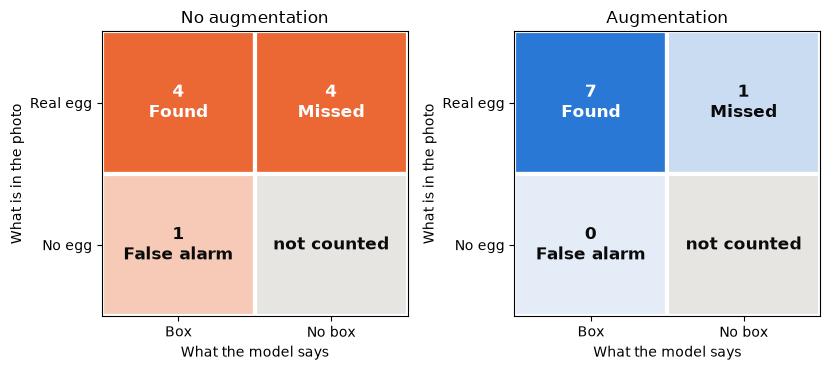

In [6]:
def count_boxes(boxes, conf):
    """Boxes with score >= conf for every (model, test photo); 0 when a model finds nothing in a photo."""
    every_pair = pd.MultiIndex.from_product(
        [list(MODELS), test_photos.image], names=["model", "image"])
    kept = boxes[boxes.score >= conf]
    return kept.groupby(["model", "image"]).size().reindex(every_pair, fill_value=0)


def egg_counts(boxes, conf):
    """Per model, on the test photos, from box counts only: found, missed and false alarms."""
    real_eggs = test_photos.set_index("image").n_items
    box_counts = count_boxes(boxes, conf).unstack("model")
    counts = {}
    for model_name in MODELS:
        n_boxes = box_counts[model_name]
        found = np.minimum(n_boxes, real_eggs)
        counts[model_name] = {
            "real_eggs": int(real_eggs.sum()),
            "found": int(found.sum()),
            "missed": int((real_eggs - found).sum()),
            "false_alarms": int((n_boxes - found).sum()),
        }
    return pd.DataFrame.from_dict(counts, orient="index").rename_axis("model")


def draw_four_cells(ax, found, missed, false_alarms, color, title):
    """Four cells like a confusion matrix: rows = what is in the photo, columns = what the model says.
    'No egg' + 'no box' cannot be counted in detection, so that cell stays gray."""
    cells = [[("Found", found), ("Missed", missed)],
             [("False alarm", false_alarms), ("not counted", None)]]
    shade = LinearSegmentedColormap.from_list("model", ["#fcfcfb", color])
    biggest = max(found, missed, false_alarms, 1)
    for row, cells_in_row in enumerate(cells):
        for col, (label, count) in enumerate(cells_in_row):
            intensity = 0.0 if count is None else 0.12 + 0.88 * count / biggest
            face = NOT_COUNTED if count is None else shade(intensity)
            ax.add_patch(Rectangle((col, row), 1, 1, facecolor=face, edgecolor="white", linewidth=3))
            text = label if count is None else f"{count}\n{label}"
            ax.text(col + 0.5, row + 0.5, text, ha="center", va="center", fontsize=12,
                    fontweight="bold", color="white" if intensity > 0.6 else INK)
    ax.set_xlim(0, 2)
    ax.set_ylim(2, 0)
    ax.set_xticks([0.5, 1.5], ["Box", "No box"])
    ax.set_yticks([0.5, 1.5], ["Real egg", "No egg"])
    ax.set(title=title, xlabel="What the model says", ylabel="What is in the photo")
    ax.grid(False)


# Boxes per test photo
boxes_per_photo = test_photos.set_index("image")[["n_items"]].rename(columns={"n_items": "real_eggs"})
box_counts = count_boxes(external_boxes, CONF_THRESHOLD).unstack("model")
for model_name in MODELS:
    boxes_per_photo[f"{model_name}: boxes"] = box_counts[model_name]
display(boxes_per_photo)

# The four cells, one grid per model
external_counts = egg_counts(external_boxes, CONF_THRESHOLD)
display(external_counts)
fig, axes = plt.subplots(1, len(MODELS), figsize=(4.2 * len(MODELS), 3.8), squeeze=False)
for ax, (model_name, row) in zip(axes[0], external_counts.iterrows()):
    draw_four_cells(ax, row.found, row.missed, row.false_alarms, MODEL_COLORS[model_name], model_name)
plt.tight_layout()
plt.show()

## 5. Confianza: ¿con qué seguridad marca cada modelo?

Las barras muestran el **puntaje más alto** que da cada modelo en cada foto de prueba, con la línea del umbral.
Una barra por encima de la línea es una detección. En una foto con 0 huevos reales, cualquier barra por encima
de la línea es una falsa alarma, y su altura dice con cuánta seguridad se equivocó el modelo.

Si una foto tiene dos huevos, la barra solo muestra el mejor. La tabla de debajo trae los mismos números.

**Aviso para el informe.** Estos puntajes **no son probabilidades calibradas**: 0,93 indica que el modelo está
muy seguro, no que acierte el 93 % de las veces. Calibrarlos requiere bastantes más fotos que las disponibles.

model,No augmentation,Augmentation,real_eggs
image,,,
a-image.png,0.73,0.93,2
a-image3.png,0.66,0.00,0
h-image.png,0.82,0.36,2
h-image2.png,0.89,0.78,1
t-image.png,0.00,0.90,2
t-image2.png,0.05,0.90,1


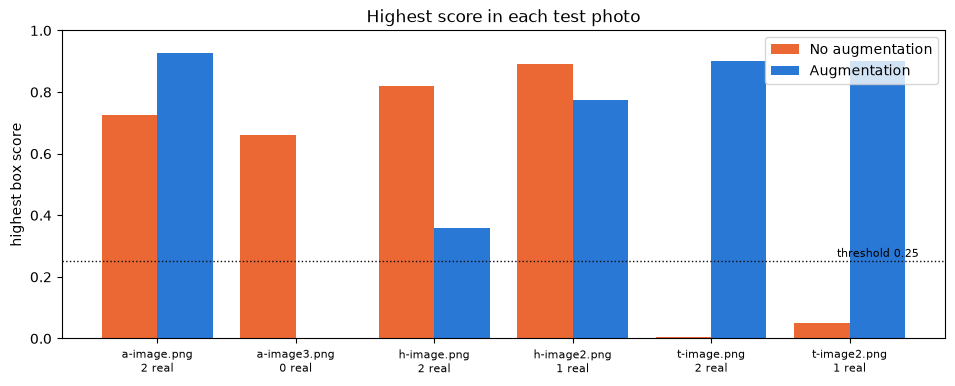

In [7]:
# Highest score of each model in each test photo (0 if the model finds no box at all)
max_score_per_photo = (
    external_boxes.groupby(["image", "model"]).score.max()
    .unstack("model")
    .reindex(index=test_photos.image, columns=list(MODELS))
    .fillna(0)
)
display(max_score_per_photo.assign(real_eggs=test_photos.set_index("image").n_items).round(2))

bar_width = 0.8 / len(MODELS)
photo_positions = np.arange(len(test_photos))
fig, ax = plt.subplots(figsize=(1.4 * len(test_photos) + 3, 4))
for index, model_name in enumerate(MODELS):
    offset = (index - (len(MODELS) - 1) / 2) * bar_width
    ax.bar(photo_positions + offset, max_score_per_photo[model_name], width=bar_width,
           color=MODEL_COLORS[model_name], label=model_name)
ax.axhline(CONF_THRESHOLD, color=INK, linestyle=":", linewidth=1)
ax.text(len(test_photos) - 0.5, CONF_THRESHOLD + 0.015, f"threshold {CONF_THRESHOLD}", ha="right", fontsize=8)
ax.set_xticks(photo_positions, [f"{photo.image}\n{photo.n_items} real" for photo in test_photos.itertuples()],
              fontsize=8)
ax.set(ylabel="highest box score", ylim=(0, 1), title="Highest score in each test photo")
ax.legend(loc="upper right")
plt.show()

## 6. ¿Qué pasaría con otros umbrales?

No cambia la decisión de 0,25: muestra la sensibilidad. Para cada valor de `CONF_CURVE`, con las fotos de
prueba, cuántos huevos se encuentran y cuántas falsas alarmas hay, por modelo. Un umbral más bajo encuentra más
huevos, pero deja pasar más falsas alarmas; uno más alto hace lo contrario.

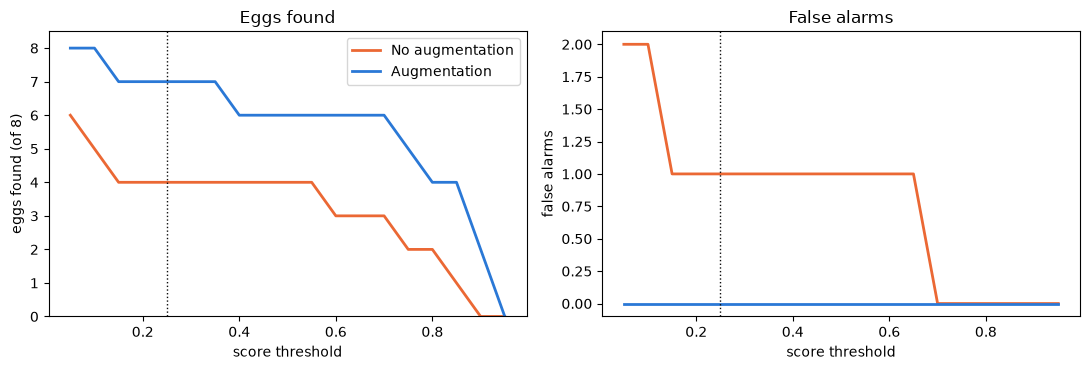

In [8]:
curve = pd.concat(
    {conf: egg_counts(external_boxes, conf) for conf in CONF_CURVE},
    names=["conf", "model"],
).reset_index()
total_real_eggs = int(test_photos.n_items.sum())

fig, (ax_found, ax_false_alarms) = plt.subplots(1, 2, figsize=(11, 3.8))
for model_name in MODELS:
    one_model = curve[curve.model == model_name]
    ax_found.plot(one_model.conf, one_model.found, label=model_name,
                  color=MODEL_COLORS[model_name], linewidth=2)
    ax_false_alarms.plot(one_model.conf, one_model.false_alarms, label=model_name,
                         color=MODEL_COLORS[model_name], linewidth=2)
for ax in (ax_found, ax_false_alarms):
    ax.axvline(CONF_THRESHOLD, color=INK, linestyle=":", linewidth=1)
    ax.set_xlabel("score threshold")
ax_found.set(ylabel=f"eggs found (of {total_real_eggs})", ylim=(0, total_real_eggs + 0.5), title="Eggs found")
ax_false_alarms.set(ylabel="false alarms", title="False alarms")
ax_found.legend()
plt.tight_layout()
plt.show()

## 7. Fotos sin huevo

Con las fotos de prueba de `n_items = 0`: ¿marca algún modelo algo donde no hay nada, y con qué puntaje?
Chula no tiene imágenes vacías, así que es la única forma de medir el rechazo de campos sin parásitos. **Un
modelo que no aparece en la tabla no encontró ninguna caja**, ni con el umbral más bajo. **Si hay una sola foto
así**, no se puede medir especificidad, solo ver un ejemplo. Conviene agregar más campos vacíos.

In [9]:
empty_fields = test_photos[~test_photos.has_eggs].image.tolist()
print(f"{len(empty_fields)} photo(s) without eggs:", empty_fields or "none")

if empty_fields:
    boxes_in_empty_fields = external_boxes[external_boxes.image.isin(empty_fields)]
    display(boxes_in_empty_fields.groupby(["image", "model"]).score.agg(
        highest_score="max",
        false_alarms=lambda scores: int((scores >= CONF_THRESHOLD).sum()),
    ).round(2))

1 photo(s) without eggs: ['a-image3.png']


,,highest_score,false_alarms
image,model,,
a-image3.png,No augmentation,0.66,1


## 8. Contraste: `valid` de Chula (410 fotos)

En fotos limpias y con las cajas reales, el emparejamiento es exacto: una caja cuenta como el huevo si se
superpone con la caja real al menos `MATCH_IOU` (0,5), y cada huevo real se empareja una sola vez. Se muestran
las mismas cuatro casillas y la distribución de los puntajes (las falsas alarmas van rayadas).

Responde si los aumentos aumentaron las falsas alarmas en fotos limpias.

**Verificación hecha:** corriendo esta sección con un umbral de 0,10, el modelo con aumentos dio recall 0,998,
precisión 0,969 y 13 falsas alarmas, igual que `src/detection/detect_crops.py`.

In [10]:
def read_ground_truth(label_file, width, height):
    """Real egg boxes of one photo, in pixels: [(x1, y1, x2, y2), ...]."""
    eggs = []
    for line in label_file.read_text().splitlines():
        parts = line.split()
        if len(parts) != 5:  # the EDA found no polygons in our labels
            continue
        center_x, center_y, box_w, box_h = map(float, parts[1:])
        eggs.append(((center_x - box_w / 2) * width, (center_y - box_h / 2) * height,
                     (center_x + box_w / 2) * width, (center_y + box_h / 2) * height))
    return eggs


def box_iou(box_a, box_b):
    """Intersection over union of two (x1, y1, x2, y2) boxes."""
    overlap_w = max(0.0, min(box_a[2], box_b[2]) - max(box_a[0], box_b[0]))
    overlap_h = max(0.0, min(box_a[3], box_b[3]) - max(box_a[1], box_b[1]))
    intersection = overlap_w * overlap_h
    area_a = (box_a[2] - box_a[0]) * (box_a[3] - box_a[1])
    area_b = (box_b[2] - box_b[0]) * (box_b[3] - box_b[1])
    return intersection / (area_a + area_b - intersection)


valid_paths = sorted(p for p in VALID_IMAGES_DIR.iterdir() if p.suffix.lower() in IMAGE_SUFFIXES)
ground_truth = {
    path.name: read_ground_truth(VALID_LABELS_DIR / f"{path.stem}.txt", *Image.open(path).size)
    for path in valid_paths
}
total_valid_eggs = sum(len(eggs) for eggs in ground_truth.values())
print(f"{len(valid_paths)} photos, {total_valid_eggs} real eggs")

valid_boxes = pd.concat(
    [detect_all(weights, valid_paths).assign(model=model_name)
     for model_name, weights in MODELS.items()],
    ignore_index=True,
)

410 photos, 413 real eggs


,real_eggs,found,missed,false_alarms,recall,precision
model,,,,,,
No augmentation,413,413,0,6,1.000,0.986
Augmentation,413,412,1,4,0.998,0.990


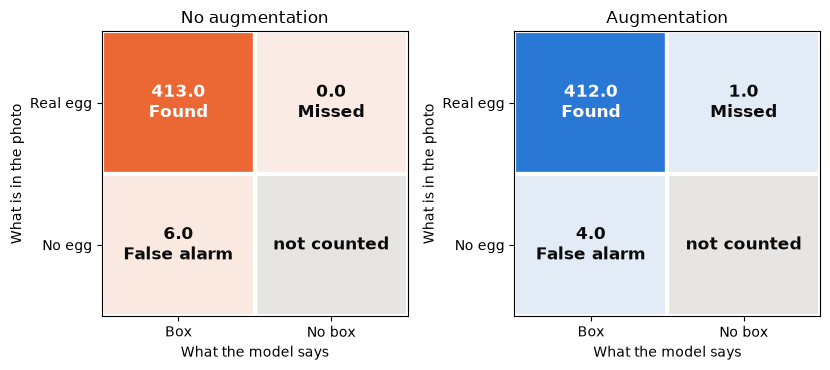

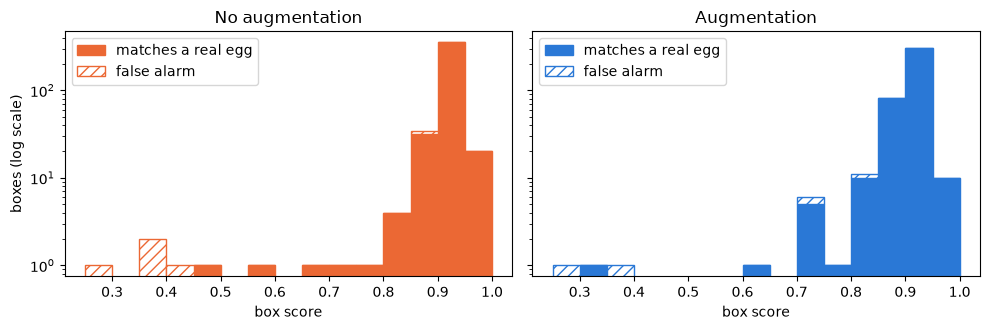

In [11]:
def mark_true_detections(boxes, conf):
    """Keep the boxes with score >= conf and add `is_egg`: True if the box matches a real egg.
    Boxes are visited from the highest score down; each real egg can be matched only once."""
    marked_groups = []
    for (model_name, image), group in boxes[boxes.score >= conf].groupby(["model", "image"]):
        unmatched_eggs = list(ground_truth[image])
        group = group.sort_values("score", ascending=False).copy()
        is_egg = []
        for box in group.itertuples():
            box_corners = (box.x1, box.y1, box.x2, box.y2)
            closest_egg = max(unmatched_eggs, key=lambda egg: box_iou(box_corners, egg), default=None)
            matches = closest_egg is not None and box_iou(box_corners, closest_egg) >= MATCH_IOU
            if matches:
                unmatched_eggs.remove(closest_egg)
            is_egg.append(matches)
        group["is_egg"] = is_egg
        marked_groups.append(group)
    return pd.concat(marked_groups)


def valid_summary(marked):
    """Found, missed and false alarms (plus recall and precision) per model on valid."""
    summary = marked.groupby("model").is_egg.agg(
        found="sum",
        false_alarms=lambda is_egg: int((~is_egg).sum()),
    ).reindex(list(MODELS), fill_value=0)
    summary["real_eggs"] = total_valid_eggs
    summary["missed"] = total_valid_eggs - summary.found
    summary["recall"] = summary.found / total_valid_eggs
    summary["precision"] = summary.found / (summary.found + summary.false_alarms).clip(lower=1)
    return summary[["real_eggs", "found", "missed", "false_alarms", "recall", "precision"]]


marked_valid = mark_true_detections(valid_boxes, CONF_THRESHOLD)
valid_counts = valid_summary(marked_valid)
display(valid_counts.round(3))

# The four cells, one grid per model
fig, axes = plt.subplots(1, len(MODELS), figsize=(4.2 * len(MODELS), 3.8), squeeze=False)
for ax, (model_name, row) in zip(axes[0], valid_counts.iterrows()):
    draw_four_cells(ax, row.found, row.missed, row.false_alarms, MODEL_COLORS[model_name], model_name)
plt.tight_layout()
plt.show()

# Scores of the boxes that match a real egg and of the false alarms (hatched)
score_bins = np.linspace(CONF_THRESHOLD, 1, 16)
fig, axes = plt.subplots(1, len(MODELS), figsize=(5 * len(MODELS), 3.4), sharey=True, squeeze=False)
for ax, model_name in zip(axes[0], MODELS):
    color = MODEL_COLORS[model_name]
    model_boxes = marked_valid[marked_valid.model == model_name]
    _, _, bar_sets = ax.hist(
        [model_boxes[model_boxes.is_egg].score, model_boxes[~model_boxes.is_egg].score],
        bins=score_bins, stacked=True, color=[color, "white"], edgecolor=color,
    )
    for bar in bar_sets[1]:
        bar.set_hatch("///")
    ax.set(title=model_name, xlabel="box score")
    ax.set_yscale("log")
    ax.legend(handles=[
        Patch(facecolor=color, edgecolor=color, label="matches a real egg"),
        Patch(facecolor="white", edgecolor=color, hatch="///", label="false alarm"),
    ])
axes[0, 0].set_ylabel("boxes (log scale)")
plt.tight_layout()
plt.show()

## 9. Conclusiones

Se escriben al final, con los números de arriba.